In [1]:
import numpy, scipy, soundfile
import tensorflow as tf
print('TensorFlow', tf.__version__)
print('NumPy', numpy.__version__, '| SciPy', scipy.__version__, '| SoundFile', soundfile.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0
NumPy 2.1.3 | SciPy 1.16.3 | SoundFile 0.14.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!wget -q --show-progress http://download.tensorflow.org/data/speech_commands_v0.01.tar.gz
!mkdir -p speech
!tar -xzf speech_commands_v0.01.tar.gz -C speech
!ls speech

speech_commands_v0. 100%[===================>]   1.39G  18.2MB/s    in 80s     
_background_noise_  five     marvin	right		  tree
bed		    four     nine	seven		  two
bird		    go	     no		sheila		  up
cat		    happy    off	six		  validation_list.txt
dog		    house    on		stop		  wow
down		    left     one	testing_list.txt  yes
eight		    LICENSE  README.md	three		  zero


Spectrogram shape: (32, 39)


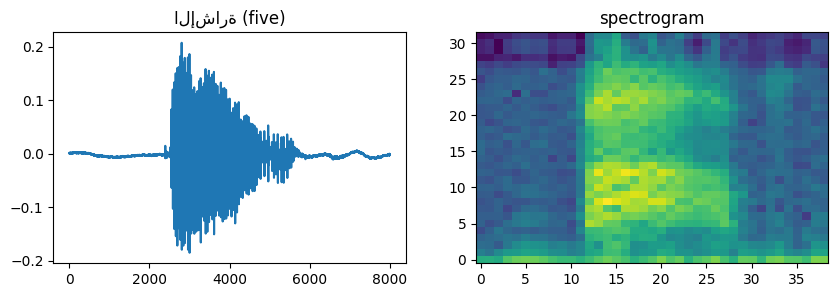

In [3]:
import os, glob
import numpy as np
import soundfile as sf
from scipy.signal import decimate
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DATA_DIR = 'speech'
DIGITS = ['zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight', 'nine']
CLASSES = DIGITS + ['background', 'unknown']   # 12 classes as in the paper
FS = 8000      # Target sampling frequency (Hz)
FRAME = 240    # Frame length (30 ms at 8 kHz)
HOP = 200      # Hop length (240 - 40 overlap)
NFFT = 256

def load_clip(path):
    x, sr = sf.read(path, dtype='float32')
    x = decimate(x, 2)                         # 16kHz -> 8kHz
    x = np.pad(x, (0, max(0, FS - len(x))))[:FS]  # Pad or trim to exactly 1 second
    return x

def spectrogram(x):
    n_frames = 1 + (len(x) - FRAME) // HOP     # = 39
    frames = np.stack([x[i * HOP:i * HOP + FRAME] for i in range(n_frames)])
    mag = np.abs(np.fft.rfft(frames, n=NFFT, axis=1))[:, :128]
    mag = mag.reshape(n_frames, 32, 4).mean(axis=2)   # Average every 4 bins -> 32 bands
    spec = 20 * np.log10(mag + 1e-6)
    return spec.T.astype('float32')            # Output shape: (32, 39)

# Quick verification on sample word 'five'
f = sorted(glob.glob(DATA_DIR + '/five/*.wav'))[0]
x = load_clip(f)
s = spectrogram(x)
print('Spectrogram shape:', s.shape)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(x); ax[0].set_title('Waveform (five)')
ax[1].imshow(s, origin='lower', aspect='auto'); ax[1].set_title('spectrogram')
plt.show()

In [4]:
val_set = set(open(DATA_DIR + '/validation_list.txt').read().split())
test_set = set(open(DATA_DIR + '/testing_list.txt').read().split())

X = {'train': [], 'val': [], 'test': []}
Y = {'train': [], 'val': [], 'test': []}

words = [d for d in sorted(os.listdir(DATA_DIR))
         if os.path.isdir(DATA_DIR + '/' + d) and not d.startswith('_')]
for w in words:
    label = CLASSES.index(w) if w in DIGITS else CLASSES.index('unknown')
    for f in tqdm(sorted(glob.glob(DATA_DIR + '/' + w + '/*.wav')), desc=w):
        rel = w + '/' + os.path.basename(f)
        split = 'test' if rel in test_set else ('val' if rel in val_set else 'train')
        X[split].append(spectrogram(load_clip(f)))
        Y[split].append(label)

# background class: 1-second random slices from noise files
rng = np.random.default_rng(0)
noise_files = glob.glob(DATA_DIR + '/_background_noise_/*.wav')
noise = [sf.read(p, dtype='float32')[0] for p in noise_files]
for split, n in [('train', 400), ('val', 50), ('test', 50)]:
    for _ in range(n):
        a = noise[rng.integers(len(noise))]
        i = rng.integers(len(a) - 16000)
        seg = decimate(a[i:i + 16000], 2)[:FS]
        X[split].append(spectrogram(seg))
        Y[split].append(CLASSES.index('background'))

for k in X:
    X[k] = np.array(X[k])[..., None]   # Shape: (N, 32, 39, 1)
    Y[k] = np.array(Y[k])
    print(k, X[k].shape, 'Samples per class:', np.bincount(Y[k], minlength=12))

bed:   0%|          | 0/1713 [00:00<?, ?it/s]

bird:   0%|          | 0/1731 [00:00<?, ?it/s]

cat:   0%|          | 0/1733 [00:00<?, ?it/s]

dog:   0%|          | 0/1746 [00:00<?, ?it/s]

down:   0%|          | 0/2359 [00:00<?, ?it/s]

...

up:   0%|          | 0/2375 [00:00<?, ?it/s]

wow:   0%|          | 0/1745 [00:00<?, ?it/s]

yes:   0%|          | 0/2377 [00:00<?, ?it/s]

zero:   0%|          | 0/2376 [00:00<?, ?it/s]

train (51488, 32, 39, 1) Samples per class: [ 1866  1892  1873  1841  1839  1844  1863  1875  1852  1875   400 32468]
val (6848, 32, 39, 1) Samples per class: [ 260  230  236  248  280  242  262  263  243  230   50 4304]
test (6885, 32, 39, 1) Samples per class: [ 250  248  264  267  253  271  244  239  257  259   50 4283]


In [5]:
MEAN = float(X['train'].mean())
STD = float(X['train'].std())
print('mean =', MEAN, ' std =', STD)
Xn = {k: ((X[k] - MEAN) / STD).astype('float32') for k in X}

mean = -35.61635208129883  std = 24.129728317260742


In [6]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model():
    return keras.Sequential([
        layers.Input(shape=(32, 39, 1)),
        layers.Conv2D(12, 3, padding='same', activation='relu', name='conv1'),
        layers.MaxPooling2D(2, padding='same'),
        layers.Dropout(0.2),
        layers.Conv2D(24, 3, padding='same', activation='relu', name='conv2'),
        layers.MaxPooling2D(2, padding='same'),
        layers.Dropout(0.2),
        layers.Conv2D(48, 3, padding='same', activation='relu', name='conv3'),
        layers.MaxPooling2D((1, 5), strides=(1, 1)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(12, name='fc'),   # Raw logits (loss computes softmax internally)
    ])

model = build_model()
model.summary()
assert model.count_params() == 40812, 'Parameter count does not match paper specification (40,812)'

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 39, 12)     │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 20, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 20, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 20, 24)     │         2,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 10, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 10, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 8, 10, 48)      │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 6, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 6, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Dense)                      │ (None, 12)             │        27,660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,812 (159.42 KB)

 Trainable params: 40,812 (159.42 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
history = model.fit(Xn['train'], Y['train'],
                    validation_data=(Xn['val'], Y['val']),
                    epochs=25, batch_size=256, verbose=2)

Epoch 1/25
202/202 - 20s - 98ms/step - accuracy: 0.6355 - loss: 1.3622 - val_accuracy: 0.7103 - val_loss: 0.9608
Epoch 2/25
202/202 - 1s - 4ms/step - accuracy: 0.7317 - loss: 0.8076 - val_accuracy: 0.8072 - val_loss: 0.5851
Epoch 3/25
202/202 - 1s - 4ms/step - accuracy: 0.7915 - loss: 0.6191 - val_accuracy: 0.8480 - val_loss: 0.4736
Epoch 4/25
202/202 - 1s - 4ms/step - accuracy: 0.8275 - loss: 0.5142 - val_accuracy: 0.8696 - val_loss: 0.4195
Epoch 5/25
202/202 - 1s - 4ms/step - accuracy: 0.8495 - loss: 0.4579 - val_accuracy: 0.8845 - val_loss: 0.3598
Epoch 6/25
202/202 - 1s - 4ms/step - accuracy: 0.8606 - loss: 0.4193 - val_accuracy: 0.8938 - val_loss: 0.3480
Epoch 7/25
202/202 - 1s - 4ms/step - accuracy: 0.8737 - loss: 0.3871 - val_accuracy: 0.8994 - val_loss: 0.3318
Epoch 8/25
202/202 - 1s - 4ms/step - accuracy: 0.8818 - loss: 0.3627 - val_accuracy: 0.9061 - val_loss: 0.3085
Epoch 9/25
202/202 - 1s - 4ms/step - accuracy: 0.8874 - loss: 0.3419 - val_accuracy: 0.9057 - val_loss: 0.3088

Test samples count: 6885
Float32 Model Accuracy: 92.97%


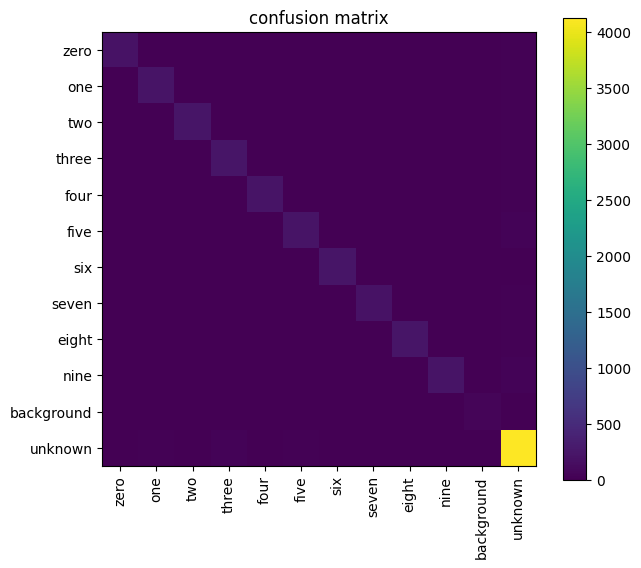

In [8]:
from sklearn.metrics import confusion_matrix
logits = model.predict(Xn['test'], verbose=0)
pred = logits.argmax(axis=1)
acc = float((pred == Y['test']).mean())
print('Test set size:', len(Y['test']))
print('Float32 model accuracy: %.2f%%' % (acc * 100))
cm = confusion_matrix(Y['test'], pred)
plt.figure(figsize=(7, 6)); plt.imshow(cm); plt.colorbar()
plt.xticks(range(12), CLASSES, rotation=90); plt.yticks(range(12), CLASSES)
plt.title('confusion matrix'); plt.show()

In [9]:
import json, shutil
os.makedirs('export', exist_ok=True)

W = {}
for name in ['conv1', 'conv2', 'conv3', 'fc']:
    w, b = model.get_layer(name).get_weights()
    W[name + '_w'] = w; W[name + '_b'] = b
np.savez('export/weights_float32.npz', **W)
model.save('export/model_float32.keras')

idx = np.random.default_rng(1).choice(len(Xn['train']), 500, replace=False)
np.savez_compressed('export/calibration.npz', x=Xn['train'][idx], y=Y['train'][idx])
np.savez_compressed('export/test.npz', x=Xn['test'], y=Y['test'])

info = {'mean': MEAN, 'std': STD, 'test_accuracy_float32': acc,
        'n_test': int(len(Y['test'])), 'classes': CLASSES,
        'tensorflow': tf.__version__, 'numpy': numpy.__version__}
json.dump(info, open('export/info.json', 'w'), indent=2)

shutil.make_archive('paper_export', 'zip', 'export')
print(os.listdir('export'))
from google.colab import files
files.download('paper_export.zip')

['weights_float32.npz', 'model_float32.keras', 'info.json', 'test.npz', 'calibration.npz']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>